# WaterTracker — When will each reservoir reach its critical level?
### A discrete-time survival model of the dry-season drawdown

**Question asked by managers.** "Issued at the end of month *t*, between October and March: in which month will this reservoir fall below its critical level, and will it last until the rains return at the end of June?"

**Why this question.** The main pipeline (`WaterTracker_pipeline.ipynb`) showed that:
- in every year, the median reservoir is dry by April, whatever the rainfall of the previous season (§5);
- one month ahead, the filling forecast is most accurate during the drawdown, from October to March (§10.5);
- a filling ratio is not what a manager plans with; a month is.

**Hypothesis H5.** A discrete-time survival model predicts the month in which each reservoir falls below the critical level (20 % of its reference area) more accurately than the reservoir's own usual drying month, and gives calibrated 80 % intervals and a probability of lasting until the end of June.

**Data.** The monthly panel produced by the main notebook (`data/gee/panel_monthly.parquet`): 100 water bodies × 92 months (January 2019 → August 2026), of which 96 can be modelled. The code shared with the API is in `ml/drying.py`; its tests are in `tests/test_drying.py`.

> As in the main notebook, each step opens with the questions of the hydrologist 💧, the programmer 💻 and the AI engineer 🤖.

---
## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

BACKEND_DIR = Path.cwd().resolve().parent
sys.path.insert(0, str(BACKEND_DIR))
import ml.drying as D

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
FIG_DIR = BACKEND_DIR / "reports" / "figures"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C_MODEL, C_CLIM, C_ALT, C_REF = "#2a78d6", "#6f6e69", "#eb6834", "#b9b8b3"
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.0.5


In [2]:
panel = pd.read_parquet(BACKEND_DIR / "data" / "gee" / "panel_monthly.parquet")
p = D.prepare(panel)
print(f"{p.reservoir_id.nunique()} modelled reservoirs | {p.month.min()} → {p.month.max()} | critical level {D.THRESHOLD:.0%}")

96 modelled reservoirs | 2019-01 → 2026-08 | critical level 20%


💧 *How is the hydrological year defined?* It starts in **July**, so that the filling peak (August-October) and the following dry season belong to the same season. Season *s* runs from July *s* to June *s + 1*. Forecasts are issued at the end of each month from **October to March**, and followed until the **end of June**, when the rains return.

🤖 *Temporal split, by season* (consistent with the main notebook, whose training ends in 2023):

| Set | Seasons (dry season) | Use |
|---|---|---|
| Training | 2018-19 (January-March issues only) to 2022-23 | learning, climatology |
| Validation | 2023-24 | model choice |
| Test | 2024-25 and 2025-26 | **final evaluation, used once** |

In [3]:
TRAIN, VALID, TEST = [2018, 2019, 2020, 2021, 2022], [2023], [2024, 2025]
curves = D.season_curves(p)
crossings = D.crossing_steps(curves)
MONTHS = ["Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "lasts"]

---
## 2. When do reservoirs cross the critical level?

💧 *First look:* for every reservoir and every complete season, the first month from October to June in which the filling ratio is below 20 %.

In [4]:
cross = crossings.dropna().astype(int)
dist_cross = cross.value_counts(normalize=True).reindex(range(0, D.SURVIVE + 1), fill_value=0)
print(f"{len(cross)} reservoir-seasons | already below in October: {dist_cross[0]:.0%} | "
      f"never below before July: {dist_cross[D.SURVIVE]:.0%}")
dist_cross.set_axis(MONTHS).round(3).to_frame("share").T

672 reservoir-seasons | already below in October: 10% | never below before July: 6%


,Oct,Nov,Dec,Jan,Feb,Mar,Apr,May,Jun,lasts
share,0.104,0.051,0.065,0.144,0.229,0.226,0.092,0.021,0.006,0.061


💧 *Is a reservoir's drying month the same every year?* If it is, the reservoir's own history is already a strong forecast, and it becomes the reference the model has to beat.

In [5]:
c = cross[cross < D.SURVIVE].reset_index(name="step")
spread = c.groupby("reservoir_id")["step"].agg(["count", "std", lambda s: s.max() - s.min()]).rename(columns={"<lambda_0>": "range"})
spread = spread[spread["count"] >= 4]
print(f"Reservoirs with ≥ 4 crossings: {len(spread)} | median year-to-year standard deviation: {spread['std'].median():.2f} months")
print(f"Share whose crossing month varies by at most 1 month across years: {(spread['range'] <= 1).mean():.0%}")

Reservoirs with ≥ 4 crossings: 91 | median year-to-year standard deviation: 0.69 months
Share whose crossing month varies by at most 1 month across years: 31%


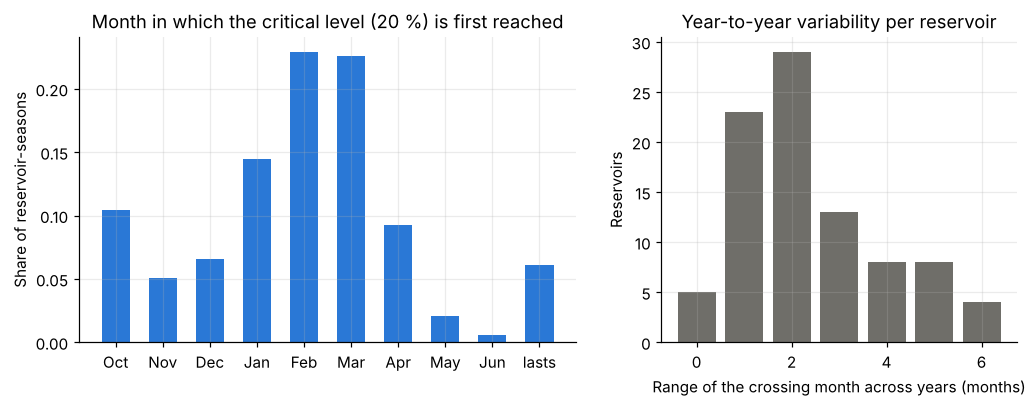

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.4, 1]})
ax1.bar(range(len(MONTHS)), dist_cross.values, color=C_MODEL, width=0.6)
ax1.set_xticks(range(len(MONTHS)), MONTHS)
ax1.set_ylabel("Share of reservoir-seasons")
ax1.set_title("Month in which the critical level (20 %) is first reached")
ax2.hist(spread["range"], bins=np.arange(-0.5, 7.5, 1), color=C_CLIM, rwidth=0.8)
ax2.set_xlabel("Range of the crossing month across years (months)")
ax2.set_ylabel("Reservoirs")
ax2.set_title("Year-to-year variability per reservoir")
fig.savefig(FIG_DIR / "fig17_drying_month.png")
plt.show()

💧 *Reading:* about 10 % of reservoirs are already below the critical level in October and 6 % last until July; the others cross from November to May, mostly in January-March, so the question "when" has a real answer to give. A reservoir's crossing month is fairly stable from year to year (median standard deviation 0.7 months), although for about two thirds of reservoirs it moved by two months or more at least once over the seasons. The reservoir's **usual drying month** is therefore a strong, transparent reference, but not a certainty.

---
## 3. Forecast rows and features

💻 One row is issued for each reservoir and each month *t* from October to March **while the reservoir is still above the critical level** (once it is below, there is nothing left to forecast). The observed outcome is the number of months until the first crossing, or "lasts until the end of June".

| Group | Features (all known at the end of month *t*) |
|---|---|
| State | filling at *t*, *t − 1*, *t − 2*; changes over 1 and 2 months; peak filling of the season so far |
| Season | June-September rainfall of the season; rainfall of the last two months; potential evaporation |
| Reservoir | log reference area; usual drying month and share of seasons it lasted (climatology); usual filling at *t* and current anomaly |
| Horizon (per month *k*) | *k*; target month; usual filling at the target month; projected filling (current anomaly carried forward) |

🤖 *Leakage control:* the climatology of a training season is computed **without that season** (leave-one-season-out); validation and test rows only see training seasons. A test checks that changing the future never changes a row's features (`tests/test_drying.py`).

In [7]:
def split(train_seasons, eval_seasons):
    rows = D.issue_rows(p, ref_seasons=train_seasons)
    tr = rows[rows.season.isin(train_seasons)].reset_index(drop=True)
    ev = rows[rows.season.isin(eval_seasons)].reset_index(drop=True)
    return tr, ev


tr, va = split(TRAIN, VALID)
counts = pd.concat([tr, va]).groupby("season").agg(rows=("reservoir_id", "size"), crossing_before_july=("event_k", lambda x: x.notna().mean()))
counts.round(3).T

season,2018,2019,2020,2021,2022,2023
rows,155.000,374.000,400.000,324.000,408.000,361.000
crossing_before_july,0.865,0.952,0.925,0.889,0.926,0.823


🤖 **Discrete-time survival.** Each row is expanded into one line per month at risk; the model learns the **hazard** *h(k)*, the probability of crossing in month *t + k* given that the reservoir has not crossed before. The survival curve *S(k) = Π (1 − h)* gives the full distribution of the crossing month: the median month, an 80 % interval (10th-90th percentiles) and the probability of lasting until the end of June. Censoring is handled naturally: a reservoir that lasts contributes "no crossing" for every month of the window.

In [8]:
pp = D.person_period(tr)
print(f"{len(tr)} training rows → {len(pp)} person-month lines | hazard rate {pp['y'].mean():.1%}")

1661 training rows → 4840 person-month lines | hazard rate 31.5%


---
## 4. References and models

| Reference | Rule |
|---|---|
| **Usual month** (climatology) | the reservoir's median crossing month over the reference seasons |
| **Projection** | the reservoir's usual drawdown, shifted by its current anomaly |
| **Linear trend** | last month's drop extrapolated linearly (a common rule of thumb) |
| **Kaplan-Meier** | probabilistic reference: observed distribution of crossing months over all reservoirs, by issue month |

| Model | Why |
|---|---|
| **Logistic hazard** | the classical discrete-time survival model: linear, interpretable |
| **Gradient-boosting hazard** (`HistGradientBoostingClassifier`) | non-linear interactions (state × month), handles missing values |

**Metrics:** error in months on the crossing month (*lasts* is coded as the month after June), share within ±1 month, Harrell's concordance index (does the model rank reservoirs by urgency correctly?), log score of the observed outcome (proper score of the whole distribution, used for model choice), Brier score of "lasts until June", coverage and width of the 80 % interval.

In [9]:
def logistic():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))


def hgb(lr, leaves, leaf):
    return HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, min_samples_leaf=leaf,
                                          l2_regularization=1.0, max_iter=300, random_state=SEED)


CANDIDATES = {
    "Logistic hazard": logistic,
    "HGB (0.03, 7 leaves, 80)": lambda: hgb(0.03, 7, 80),
    "HGB (0.05, 15 leaves, 40)": lambda: hgb(0.05, 15, 40),
    "HGB (0.1, 31 leaves, 20)": lambda: hgb(0.1, 31, 20),
}


def evaluate(train, ev, makers):
    out, models, dists = [], {}, {}
    for name, pred in [("Usual month", D.baseline_climatology(ev)), ("Projection", D.baseline_projection(ev)),
                       ("Linear trend", D.baseline_trend(ev))]:
        out.append({"model": name, **D.point_metrics(pred, ev), "C_index": D.concordance(pred, ev)})
    km = D.baseline_kaplan_meier(train, ev)
    out.append({"model": "Kaplan-Meier", **D.point_metrics(D.summarise(km, ev)["k_q50"].to_numpy(), ev),
                "C_index": np.nan, **D.distribution_metrics(km, ev)})
    lines = D.person_period(train)
    for name, make in makers.items():
        m = make().fit(lines[D.FEATURES], lines["y"])
        dist = D.predict_distribution(m, ev)
        k50 = D.summarise(dist, ev)["k_q50"].to_numpy()
        out.append({"model": name, **D.point_metrics(k50, ev), "C_index": D.concordance(k50, ev), **D.distribution_metrics(dist, ev)})
        models[name], dists[name] = m, dist
    return pd.DataFrame(out).set_index("model"), models, dists


valid_scores, _, _ = evaluate(tr, va, CANDIDATES)
valid_scores.round(3)

,MAE_months,within_1_month,exact_month,survive_accuracy,C_index,log_score,brier_survive,coverage_80,width_80_months
model,,,,,,,,,
Usual month,0.765,0.801,0.562,0.856,0.837,NaN,NaN,NaN,NaN
Projection,0.917,0.784,0.535,0.812,0.849,NaN,NaN,NaN,NaN
Linear trend,1.928,0.501,0.355,0.701,0.704,NaN,NaN,NaN,NaN
Kaplan-Meier,1.435,0.673,0.296,0.823,NaN,-1.636,0.148,0.839,3.548
Logistic hazard,0.684,0.850,0.584,0.861,0.887,-1.384,0.131,0.861,1.474
"HGB (0.03, 7 leaves, 80)",0.632,0.856,0.620,0.870,0.899,-1.207,0.122,0.861,1.335
"HGB (0.05, 15 leaves, 40)",0.632,0.856,0.623,0.864,0.898,-1.414,0.128,0.814,1.072
"HGB (0.1, 31 leaves, 20)",0.604,0.867,0.620,0.870,0.897,-1.944,0.129,0.759,0.609


In [10]:
learned = valid_scores.loc[list(CANDIDATES)]
SELECTED = learned["log_score"].idxmax()
print(f"Selected on validation (best log score): {SELECTED}")

Selected on validation (best log score): HGB (0.03, 7 leaves, 80)


🤖 *Choice rule, fixed before looking at the test:* the best **log score** on the validation season, because it judges the whole distribution (month, interval and probability of lasting), not only the median. The logistic hazard is kept as a comparison model in the test.

---
## 5. Final evaluation on the test seasons (2024-25 and 2025-26)

🤖 The selected configuration and the logistic hazard are retrained on training + validation seasons, with the climatology recomputed on those seasons, then evaluated once on the two test seasons.

In [11]:
tr_full, te = split(TRAIN + VALID, TEST)
FINAL = {SELECTED: CANDIDATES[SELECTED], "Logistic hazard": CANDIDATES["Logistic hazard"]}
test_scores, final_models, test_dists = evaluate(tr_full, te, FINAL)
print(f"{len(te)} forecast rows on the test seasons")
test_scores.round(3)

748 forecast rows on the test seasons


,MAE_months,within_1_month,exact_month,survive_accuracy,C_index,log_score,brier_survive,coverage_80,width_80_months
model,,,,,,,,,
Usual month,0.525,0.941,0.576,0.984,0.853,NaN,NaN,NaN,NaN
Projection,0.968,0.806,0.509,0.846,0.816,NaN,NaN,NaN,NaN
Linear trend,2.023,0.511,0.311,0.667,0.698,NaN,NaN,NaN,NaN
Kaplan-Meier,1.182,0.726,0.324,0.904,NaN,-1.602,0.084,0.901,3.951
"HGB (0.03, 7 leaves, 80)",0.472,0.937,0.616,0.977,0.881,-0.974,0.020,0.926,1.473
Logistic hazard,0.437,0.951,0.622,0.983,0.890,-0.952,0.016,0.949,1.701


🤖 **Is the gain over the usual month robust?** Rows of the same reservoir are correlated, so the bootstrap resamples **whole reservoirs** (2,000 replicates).

In [12]:
obs = D.observed_k(te)
errors = pd.DataFrame({"reservoir_id": te["reservoir_id"], "issue_step": te["issue_step"], "anom_issue": te["anom_issue"],
                       "Usual month": np.abs(D.baseline_climatology(te) - obs)})
for name, dist in test_dists.items():
    errors[name] = np.abs(D.summarise(dist, te)["k_q50"].to_numpy() - obs)

rng = np.random.default_rng(SEED)
ids = errors["reservoir_id"].unique()
sums = errors.groupby("reservoir_id")[["Usual month", *test_dists]].sum()
sizes = errors.groupby("reservoir_id").size()
rows_out = []
for name in test_dists:
    gains = []
    for _ in range(2000):
        s = rng.choice(ids, len(ids))
        gains.append((sums.loc[s, "Usual month"].sum() - sums.loc[s, name].sum()) / sizes.loc[s].sum())
    gains = np.array(gains)
    rows_out.append({"model": name, "MAE_gain_months": errors["Usual month"].mean() - errors[name].mean(),
                     "CI95_low": np.percentile(gains, 2.5), "CI95_high": np.percentile(gains, 97.5),
                     "p_bootstrap": (gains <= 0).mean()})
significance = pd.DataFrame(rows_out).set_index("model")
significance.round(3)

,MAE_gain_months,CI95_low,CI95_high,p_bootstrap
model,,,,
"HGB (0.03, 7 leaves, 80)",0.053,-0.023,0.134,0.083
Logistic hazard,0.088,0.016,0.165,0.006


💧 *Where does the model help?* By issue month (October is the end-of-rains assessment) and by the current anomaly (is the reservoir fuller or emptier than usual for the month?).

In [13]:
by_month = errors.groupby("issue_step")[["Usual month", *test_dists]].mean()
by_month.index = [MONTHS[i] for i in by_month.index]
errors["anomaly"] = pd.qcut(errors["anom_issue"], 3, labels=["emptier than usual", "near usual", "fuller than usual"])
by_anomaly = errors.groupby("anomaly", observed=True)[["Usual month", *test_dists]].mean()
display(by_month.round(3))
by_anomaly.round(3)

,Usual month,"HGB (0.03, 7 leaves, 80)",Logistic hazard
Oct,0.600,0.688,0.594
Nov,0.586,0.533,0.491
Dec,0.556,0.400,0.369
Jan,0.496,0.325,0.374
Feb,0.337,0.337,0.303
Mar,0.324,0.324,0.297


,Usual month,"HGB (0.03, 7 leaves, 80)",Logistic hazard
anomaly,,,
emptier than usual,0.492,0.476,0.468
near usual,0.382,0.398,0.337
fuller than usual,0.703,0.542,0.506


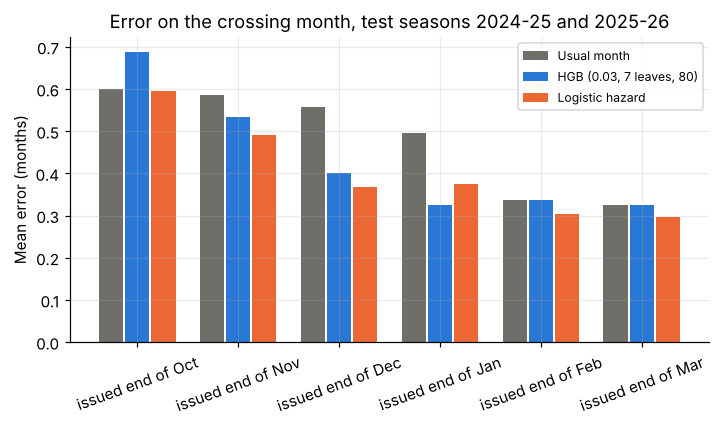

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(len(by_month))
for i, (name, color) in enumerate([("Usual month", C_CLIM), (SELECTED, C_MODEL), ("Logistic hazard", C_ALT)]):
    ax.bar(x + (i - 1) * 0.26, by_month[name], width=0.24, color=color, label=name)
ax.set_xticks(x, [f"issued end of {m}" for m in by_month.index], rotation=20)
ax.set_ylabel("Mean error (months)")
ax.set_title("Error on the crossing month, test seasons 2024-25 and 2025-26")
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "fig18_drying_error_by_issue.png")
plt.show()

---
## 6. Uncertainty and explainability

🤖 *Are the 80 % intervals honest?* Coverage above 80 % means the intervals are conservative (too wide), below means over-confident. The probability of lasting until June is judged by the Brier score against the Kaplan-Meier reference.

In [15]:
test_scores.loc[["Kaplan-Meier", *test_dists], ["log_score", "brier_survive", "coverage_80", "width_80_months"]].round(3)

,log_score,brier_survive,coverage_80,width_80_months
model,,,,
Kaplan-Meier,-1.602,0.084,0.901,3.951
"HGB (0.03, 7 leaves, 80)",-0.974,0.020,0.926,1.473
Logistic hazard,-0.952,0.016,0.949,1.701


In [16]:
lines_te = D.person_period(te)
imp = permutation_importance(final_models[SELECTED], lines_te[D.FEATURES], lines_te["y"], n_repeats=5,
                             random_state=SEED, scoring="neg_log_loss")
importance = pd.Series(imp.importances_mean, index=D.FEATURES).sort_values(ascending=False)
importance.head(10).round(4).to_frame("increase in log loss")

,increase in log loss
clim_fill_target,0.1787
projected_fill,0.0633
k,0.0258
target_step,0.0189
clim_cross,0.0148
fill_l0,0.0133
dfill_1,0.0030
log_a_ref,0.0023
rain_season,0.0020
rain_recent,0.0016


🤖 *Reading:* the hazard depends mostly on the reservoir's usual filling at the target month and on the projected filling (usual drawdown shifted by the current anomaly), then on the horizon. The current filling matters through that projection. The model is, in effect, a calibrated version of "how far from the usual curve is this reservoir this year".

---
## 7. What a bulletin looks like

💻 `D.forecast_drying` is the function an API or a monthly bulletin would call. Below, the forecast issued at the **end of October 2025** (test season) with the model trained on seasons up to 2023-24, compared with what actually happened.

In [17]:
bulletin = D.forecast_drying(final_models[SELECTED], panel, "2025-10", ref_seasons=TRAIN + VALID)
issue_rows = te[te["date"] == "2025-10-01"].set_index("reservoir_id")
happened = issue_rows["event_k"].map(lambda k: "after June" if np.isnan(k) else f"{pd.Timestamp('2025-10-01') + pd.DateOffset(months=int(k)):%Y-%m}")
bulletin["observed"] = bulletin["reservoir_id"].map(happened)
print(f"{len(bulletin)} reservoirs above the critical level at the end of October 2025")
bulletin.head(12)

86 reservoirs above the critical level at the end of October 2025


,reservoir_id,issue_month,fill_now,critical_month,earliest_80,latest_80,p_lasts_to_june,usual_month,observed
0,J31,2025-10,0.255,2025-11,2025-11,2026-01,0.0,2025-12,2025-12
1,J41,2025-10,0.779,2025-11,2025-11,2026-01,0.0,2025-11,2026-01
2,R29,2025-10,0.411,2025-11,2025-11,2026-01,0.0,2025-11,2025-11
3,J15,2025-10,0.773,2025-12,2025-12,2026-01,0.0,2025-12,2025-12
4,J18,2025-10,0.556,2025-12,2025-12,2026-01,0.0,2025-12,2025-12
5,J29,2025-10,0.561,2025-12,2025-11,2025-12,0.0,2025-12,2025-12
6,J42,2025-10,0.631,2025-12,2025-11,2026-01,0.0,2025-12,2025-11
7,J49,2025-10,0.206,2025-12,2025-11,2026-01,0.0,2026-01,2025-12
8,R13,2025-10,0.893,2025-12,2025-12,2026-02,0.0,2025-12,2026-03
9,J12,2025-10,0.539,2026-01,2025-12,2026-02,0.0,2026-01,2026-01


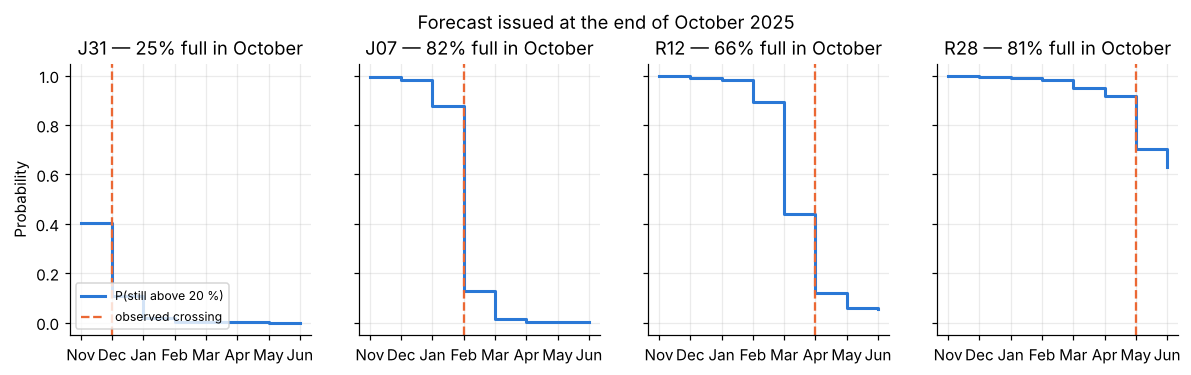

In [18]:
oct25 = te[te["date"] == "2025-10-01"].reset_index(drop=True)
dist_oct = D.predict_distribution(final_models[SELECTED], oct25)
picks = oct25.assign(k50=D.summarise(dist_oct, oct25)["k_q50"]).sort_values("k50")
picks = picks.iloc[np.linspace(0, len(picks) - 1, 4).astype(int)]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, (i, r) in zip(axes, picks.iterrows()):
    surv = 1 - np.cumsum(dist_oct[i, :int(r["K"])])
    ax.step(range(1, int(r["K"]) + 1), surv, where="post", color=C_MODEL, lw=2, label="P(still above 20 %)")
    if not np.isnan(r["event_k"]):
        ax.axvline(r["event_k"], color=C_ALT, ls="--", label="observed crossing")
    ax.set_xticks(range(1, 9), MONTHS[1:9])
    ax.set_title(f"{r['reservoir_id']} — {r['fill_l0']:.0%} full in October")
axes[0].set_ylabel("Probability")
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Forecast issued at the end of October 2025", y=1.03)
fig.savefig(FIG_DIR / "fig19_drying_survival_examples.png")
plt.show()

---
## 8. Robustness: the "dried up" level (5 %)

💧 Some users care less about the critical level than about the moment the reservoir is practically empty. The same pipeline is rerun with a 5 % threshold, without re-tuning.

In [19]:
rows5 = D.issue_rows(p, ref_seasons=TRAIN + VALID, threshold=0.05)
tr5 = rows5[rows5.season.isin(TRAIN + VALID)].reset_index(drop=True)
te5 = rows5[rows5.season.isin(TEST)].reset_index(drop=True)
lines5 = D.person_period(tr5)
m5 = CANDIDATES[SELECTED]().fit(lines5[D.FEATURES], lines5["y"])
dist5 = D.predict_distribution(m5, te5)
robust = pd.DataFrame([
    {"model": "Usual month", **D.point_metrics(D.baseline_climatology(te5), te5)},
    {"model": SELECTED, **D.point_metrics(D.summarise(dist5, te5)["k_q50"].to_numpy(), te5), **D.distribution_metrics(dist5, te5)},
]).set_index("model")
robust.round(3)

,MAE_months,within_1_month,exact_month,survive_accuracy,log_score,brier_survive,coverage_80,width_80_months
model,,,,,,,,
Usual month,0.785,0.835,0.511,0.898,NaN,NaN,NaN,NaN
"HGB (0.03, 7 leaves, 80)",0.649,0.869,0.561,0.905,-1.094,0.075,0.917,2.196


💧 *Reading:* with the 5 % threshold the usual month is a weaker reference, because the date at which a reservoir is completely empty varies more from year to year, and the model's advantage is larger (see the table). The intervals widen accordingly.

---
## 9. Summary

In [20]:
s, t = significance, test_scores
print(f"Test seasons 2024-25 and 2025-26: {len(te)} forecasts")
print(f"Usual month: error {t.loc['Usual month', 'MAE_months']:.2f} months, within ±1 month {t.loc['Usual month', 'within_1_month']:.0%}")
for name in test_dists:
    print(f"{name}: error {t.loc[name, 'MAE_months']:.2f} months, within ±1 month {t.loc[name, 'within_1_month']:.0%}, "
          f"C-index {t.loc[name, 'C_index']:.2f}, 80 % coverage {t.loc[name, 'coverage_80']:.0%}, "
          f"gain {s.loc[name, 'MAE_gain_months']:+.2f} months (p = {s.loc[name, 'p_bootstrap']:.3f})")

Test seasons 2024-25 and 2025-26: 748 forecasts
Usual month: error 0.53 months, within ±1 month 94%
HGB (0.03, 7 leaves, 80): error 0.47 months, within ±1 month 94%, C-index 0.88, 80 % coverage 93%, gain +0.05 months (p = 0.083)
Logistic hazard: error 0.44 months, within ±1 month 95%, C-index 0.89, 80 % coverage 95%, gain +0.09 months (p = 0.006)


**Answer to H5 (values of this run, see the tables above).**
- The reservoir's **usual drying month** is already a strong forecast: on the test seasons it is within one month of the observed crossing in 94 % of cases. Any product can show this month at no modelling cost.
- The survival models improve on it only modestly (0.05 to 0.09 months on average; significant for the logistic hazard only). The gain is concentrated on forecasts issued **from November to January** and on reservoirs that are **fuller than usual**, i.e. unusual situations where the history alone is misleading. At the end of October, the usual month is as good as the models, or better.
- For the "dried up" level (5 %), whose date varies more, the model's advantage is larger.
- Their main added value is elsewhere: a **full distribution** (an 80 % interval about one and a half months wide, conservative on the test seasons) and a **well-calibrated probability of lasting until the end of June**, far better than the population reference (Brier score).
- The model chosen on validation (gradient boosting) and the logistic hazard are close; the logistic model did slightly better on the test. With two test seasons, this difference should be confirmed on the 2026-27 season before choosing one for production.

**Operational use.** A dry-season bulletin can show, for each reservoir: its usual drying month (transparent), the model's most likely month and 80 % range, and the probability of lasting until June. `D.forecast_drying` produces this table from the monthly panel.

**Limitations.** Seven seasons of history and only two test seasons; the critical level is defined on area, not volume; withdrawals are not observed; reservoirs share the same weather, so seasons, not reservoirs, are the real unit of replication.